In [71]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_score
from sklearn import svm
from sklearn.model_selection import cross_validate
from sklearn.metrics import recall_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso

#df = pd.read_csv("/content/cat_to_num.csv")
#df = pd.read_csv("/content/one_hot.csv")
#df = pd.read_csv("/content/thisone.csv")
df = pd.read_csv("/content/fingers_crossed.csv")


df.drop("final_result",axis = 1).columns
features = df.drop("final_result",axis = 1)

df.isna().sum()          # per column

df.to_csv("stud_activities.csv")
df.columns
df=df.drop(["scoreCA","Unnamed: 0","region","studied_credits"],axis = 1)
#df = df[df["final_result"] != 0]
df["final_result"] = df["final_result"].replace({
    0: 0,
    1: 1,
    2: 1,
})
df.columns
y = df["final_result"]

passes = (df['final_result'] == 1).sum()
fails  = (df['final_result'] == 0).sum()
df["final_result"].unique()
print(fails)
print(passes)


6373
13866


3824
lasso
              precision    recall  f1-score   support

         0.0       0.47      0.76      0.58      1275
         1.0       0.85      0.60      0.70      2773

    accuracy                           0.65      4048
   macro avg       0.66      0.68      0.64      4048
weighted avg       0.73      0.65      0.66      4048

[[ 971  304]
 [1111 1662]]
0.6504446640316206
none
              precision    recall  f1-score   support

         0.0       0.50      0.79      0.61      1274
         1.0       0.87      0.63      0.73      2774

    accuracy                           0.68      4048
   macro avg       0.68      0.71      0.67      4048
weighted avg       0.75      0.68      0.69      4048

[[1009  265]
 [1017 1757]]
0.683300395256917


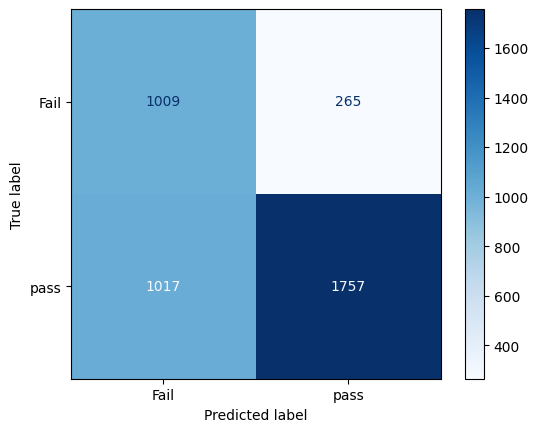

In [73]:
from sklearn.linear_model import LinearRegression
features = df.drop("final_result",axis = 1).columns
scaler = StandardScaler()
X_multi = df[features]
RANDOM_STATE = 42
X_train_m, X_temp, y_train_m, y_temp = train_test_split(
    X_multi, y, test_size=0.40, random_state=RANDOM_STATE, stratify=y
)
X_valid, X_test_m, y_valid, y_test_m = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)
#X_scaled = scaler.fit_transform(X_train_m)
#X_scaled_test = scaler.fit_transform(X_test_m)
#print(y_train_m['final_result'] == 2).sum())
print((y_train_m ==0).sum())
model_multi = Pipeline([("scaler", StandardScaler()),("model", LogisticRegression(max_iter=1000, random_state=42,class_weight ="balanced"))])
model_lasso = Pipeline([("scaler", StandardScaler()),("model", LogisticRegression(penalty='l1',C=0.01,max_iter=5000,solver = "saga",class_weight ="balanced"))])



#model_lasso = Pipeline([("scaler", StandardScaler()),("model", Lasso(alpha = 100,max_iter=5000))])

model_multi.fit(X_train_m, y_train_m)
model_lasso.fit(X_train_m, y_train_m)

y_pred_m = model_multi.predict(X_valid)
y_pred_m2 = model_lasso.predict(X_test_m)

#print("Accuracy:", accuracy_score(y_test_m, y_pred_m))

#print(classification_report(y_train_m, y_pred_m2))

#print(confusion_matrix(y_test_m, y_pred_m))
#regression_metrics(y_test_m, y_pred_m)
from sklearn.metrics import accuracy_score

print("lasso")
print(classification_report(y_test_m,y_pred_m2))
print(confusion_matrix(y_test_m,y_pred_m2))
print(accuracy_score(y_test_m,y_pred_m2))
print("none")
print(classification_report(y_valid,y_pred_m))
print(confusion_matrix(y_valid,y_pred_m))
print(accuracy_score(y_valid, y_pred_m))

ConfusionMatrixDisplay.from_predictions(
    y_valid, y_pred_m,
    display_labels=["Fail", "pass"],
    cmap="Blues"
)
plt.savefig("log_confuse.png")

In [56]:
from sklearn.model_selection import train_test_split, StratifiedKFold

valid_pred = model_lasso.predict(X_valid)
print(classification_report(y_valid, valid_pred))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


safe_scores = cross_validate(
  model_lasso, X_train_m, y_train_m, cv=cv,
    scoring=["accuracy", "precision_macro", "recall_macro", "f1_macro"]
)
print("Mean CV F1 with pipeline:", round(safe_scores["test_f1_macro"].mean(), 3))
print(safe_scores["test_recall_macro"].mean())
print(safe_scores["test_precision_macro"].mean())
print(safe_scores["test_accuracy"].mean())
safe_scores

              precision    recall  f1-score   support

         0.0       0.49      0.80      0.60      1274
         1.0       0.87      0.61      0.72      2774

    accuracy                           0.67      4048
   macro avg       0.68      0.70      0.66      4048
weighted avg       0.75      0.67      0.68      4048

Mean CV F1 with pipeline: 0.662
0.7053144946598435
0.6774651208039374
0.6718274786472898


{'fit_time': array([1.30672526, 1.99297929, 1.02236557, 1.57900333, 1.11609721]),
 'score_time': array([0.01502323, 0.01377749, 0.01327562, 0.0187583 , 0.01874161]),
 'test_accuracy': array([0.65994236, 0.67805681, 0.67641005, 0.66268534, 0.68204283]),
 'test_precision_macro': array([0.66825629, 0.68346168, 0.67709815, 0.67722521, 0.68128427]),
 'test_recall_macro': array([0.69459842, 0.71241005, 0.70520519, 0.70435052, 0.71000829]),
 'test_f1_macro': array([0.65060901, 0.66837657, 0.66517211, 0.65505997, 0.67052319])}

              precision    recall  f1-score   support

         0.0       0.47      0.76      0.58      1275
         1.0       0.85      0.61      0.71      2773

    accuracy                           0.66      4048
   macro avg       0.66      0.69      0.65      4048
weighted avg       0.73      0.66      0.67      4048



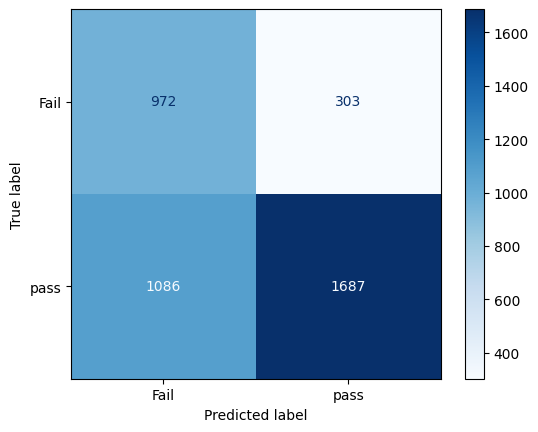

In [57]:
X_trainval = pd.concat([X_train_m, X_valid])
y_trainval = pd.concat([y_train_m, y_valid])
model_lasso.fit(X_trainval, y_trainval)
test_pred = model_lasso.predict(X_test_m)
ConfusionMatrixDisplay.from_predictions(
    y_test_m, test_pred,
    display_labels=["Fail", "pass"],
    cmap="Blues"
)
print(classification_report(y_test_m, test_pred))
plt.savefig("on_test_set")

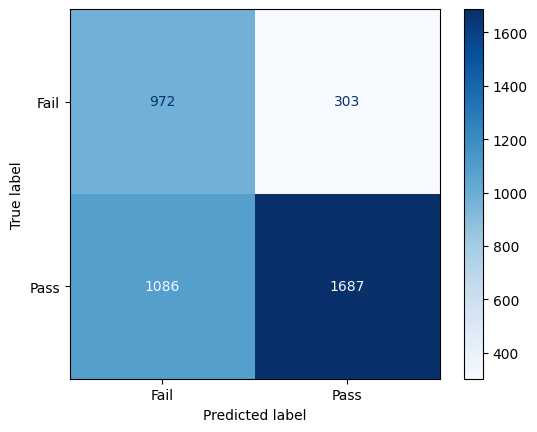

In [59]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test_m,test_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Fail', 'Pass']
)

display.plot(cmap='Blues')

In [34]:
model = LogisticRegression(
    solver='saga',
    max_iter=5000,
    random_state=42
)
param_grid = {
    'penalty':  ['l1'],
    'C': [0.0001,0.001, 0.01, 0.1, 1, 10, 10]
}

grid_search =GridSearchCV(
    model,param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)
#10

In [35]:
X_scaled = scaler.fit_transform(X_train_m)
#X_scaled_test = scaler.fit_transform(X_test_m)
grid_search.fit(X_scaled, y_train_m)

print("Best parameters:", grid_search.best_params_)
print("Best CV score:", grid_search.best_score_)

Best parameters: {'C': 10, 'penalty': 'l1'}
Best CV score: 0.7011887727014561


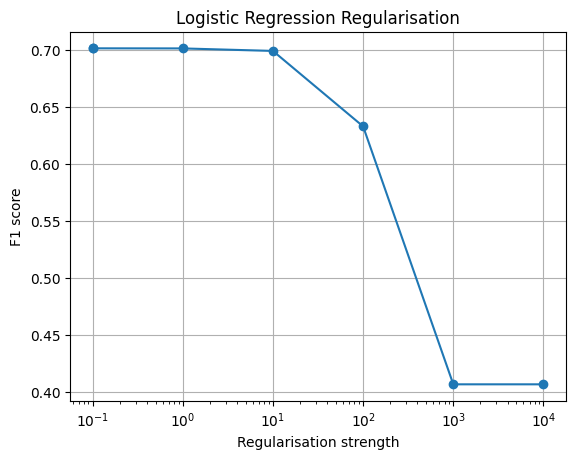

array([1.e+04, 1.e+03, 1.e+02, 1.e+01, 1.e+00, 1.e-01, 1.e-01])

In [80]:

results = grid_search.cv_results_

plt.plot(
    1/np.array(param_grid['C']),
    results['mean_test_score'],
    marker='o'
)
plt.xscale('log')
plt.xlabel('Regularisation strength')
plt.ylabel('F1 score')
plt.title('Logistic Regression Regularisation')
plt.grid()
plt.savefig("score")
plt.show()
1/np.array(param_grid['C'])

In [38]:
best_model = grid_search.best_estimator_

coefficients = pd.DataFrame({
    'Feature': features,
    'Coefficient': best_model.coef_[0]
})

coefficients = coefficients.sort_values(
    by='Coefficient'
)

print(coefficients)

              Feature  Coefficient
19               page    -0.569641
25            subpage    -0.491486
8            dualpane    -0.120938
6            gender_M    -0.110378
22     repeatactivity    -0.089532
14       htmlactivity    -0.082982
4        disability_Y    -0.047287
24      sharedsubpage    -0.017059
17       ouelluminate    -0.013106
3        disability_N     0.047287
2            age_band     0.050056
9        externalquiz     0.083095
12           glossary     0.085983
5            gender_F     0.110378
20      questionnaire     0.114608
1            imd_band     0.149602
15      oucollaborate     0.202295
0   highest_education     0.248744
26                url     0.274280
11            forumng     0.277364
10             folder     0.347967
16          oucontent     0.434276
13           homepage     0.447415
18             ouwiki     0.476753
7            dataplus     0.519110
23           resource     0.583099
21               quiz     0.609643


In [40]:

logistic_model = model_multi[-1]

# Get coefficients
coefficients = logistic_model.coef_[0]

# Get feature names
feature_names = X_train_m.columns

# Create dataframe
importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})


In [43]:
# Standard logistic regression (no regularisation)

model_multi = Pipeline([("scaler", StandardScaler()),("model", LogisticRegression(max_iter=1000, random_state=42))])
model_lasso = Pipeline([("scaler", StandardScaler()),("model", LogisticRegression(class_weight = "balanced",penalty='l1',C=0.01,max_iter=5000,solver = "saga"))])

model_none = LogisticRegression(
    penalty=None,
    max_iter=5000
)


# Lasso (L1)



model_multi.fit(X_train_m, y_train_m)
model_lasso.fit(X_train_m, y_train_m)
feature_names = model_multi.named_steps['scaler'].get_feature_names_out()

In [81]:
import pandas as pd


coefficients = pd.DataFrame({
    'Feature': feature_names,
    'No regularisation': model_multi.named_steps['model'].coef_[0],
    'Lasso (L1)': model_lasso.named_steps['model'].coef_[0]
})
# Sort features by their maximum absolute coefficient
coefficients['importance'] = coefficients[
    ['No regularisation', 'Lasso (L1)']
].abs().max(axis=1)

coefficients = coefficients.sort_values(
    'importance',
    ascending=True
)

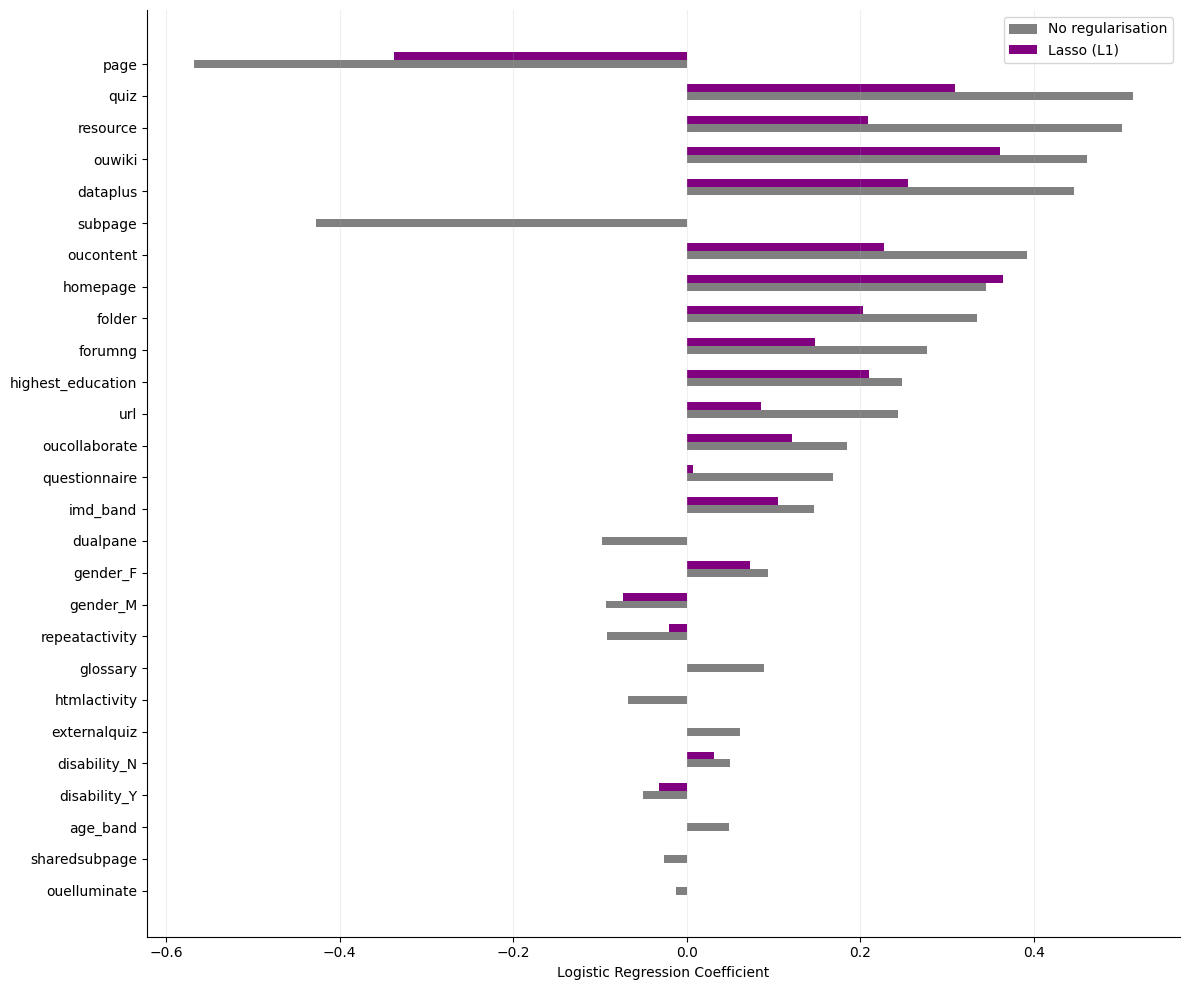

In [82]:
import matplotlib.pyplot as plt
import numpy as np

# Set positions
y = np.arange(len(coefficients))
height = 0.25

fig, ax = plt.subplots(figsize=(12, 10))

# Plot three sets of bars
ax.barh(
    y ,
    coefficients['No regularisation'],
    height,
    label='No regularisation',
    color='grey'
)


ax.barh(
    y + height,
    coefficients['Lasso (L1)'],
    height,
    label='Lasso (L1)',
    color='purple'
)

# Labels and formatting
ax.set_yticks(y)
ax.set_yticklabels(coefficients['Feature'])

ax.set_xlabel('Logistic Regression Coefficient')

#ax.axvline(x=0, color='black', linewidth=1)

ax.legend()
ax.grid(axis='x', alpha=0.2)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig("regularisation")
plt.show()

In [92]:
from sklearn.model_selection import cross_val_score
from sklearn import svm
from sklearn.model_selection import cross_validate
from sklearn.metrics import recall_score
scoring = ['precision_macro', 'recall_macro']

In [64]:
scores = cross_validate(model_multi, X_multi, y, scoring=scoring)

In [65]:
scores

{'fit_time': array([2.61296988, 3.86802888, 2.37355518, 3.92928624, 1.13989353]),
 'score_time': array([0.01901078, 0.01574588, 0.01007843, 0.01348734, 0.0099721 ]),
 'test_precision_macro': array([0.65945166, 0.65618677, 0.70583169, 0.7418196 , 0.84676313]),
 'test_recall_macro': array([0.67609582, 0.6016474 , 0.60557448, 0.64382554, 0.6931038 ])}